# LEMBAR PENGERJAAN UJIAN TENGAH SEMESTER (UTS)
## MATA KULIAH: GRAF SAINS DATA (GASAL 2026/2027)
**Program Studi:** S1 Sains Data — Fakultas Matematika dan Ilmu Pengetahuan Alam  
**Universitas:** Universitas Negeri Surabaya (UNESA)  
**Dosen Pengampu:** TIM Dosen Graf Sains Data  
**Materi Pokok:** Python Driver untuk Neo4j dan Sistem Rekomendasi Graf  
**Dataset:** RetailRocket eCommerce Dataset (`events.csv`)  

---
### Identitas Mahasiswa
| Informasi | Keterangan |
| :--- | :--- |
| **Nama Lengkap** | **Michael Fahrudin** |
| **NIM** | **23031554139** |
| **Kelas** | Sains Data 2023 |
| **Periode Fold Training (P1)** | **10 September 2015 – 12 September 2015** (3 Hari) |
| **Periode Fold Testing (P2)** | **13 September 2015 – 14 September 2015** (2 Hari) |
| **Database Engine** | Neo4j AuraDB (Cloud Instance) |

> **Catatan Keunikan Filter:** Kombinasi periode waktu di atas telah diverifikasi **100% unik** dan tidak bertabrakan dengan daftar pemilihan rekan sekelas lainnya.

---
# BAGIAN 1: TUGAS PENDAHULUAN

### 1.1 Persiapan dan Perkenalan Lingkungan
Pada bagian ini dilakukan penyiapan dependensi Python yang dibutuhkan untuk analisis data, manipulasi graf, komputasi matriks VSM, serta koneksi ke instance Neo4j AuraDB.

In [5]:
import os
import time
import json
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from neo4j import GraphDatabase, RoutingControl

# Konfigurasi visualisasi matplotlib
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = 'Arial'

print("Seluruh dependensi berhasil dimuat dengan sukses!")

Seluruh dependensi berhasil dimuat dengan sukses!


### 1.2 Mempelajari Penggunaan Driver Neo4J & Pertanyaan Checkpoint
Koneksi dilakukan menggunakan protokol terenkripsi `neo4j+ssc://` ke instance Neo4j AuraDB di Cloud.

In [6]:
# Kredensial koneksi Neo4j AuraDB
URI = "neo4j+ssc://81a4f7a1.databases.neo4j.io"
AUTH = ("81a4f7a1", "M26SjhxYPT8o-5w7-zRzyJNhG80Bok-l1VqeABIsb_U")
DATABASE_NAME = "81a4f7a1"

# Fungsi pembuatan simpul Person dan relasi KNOWS (Sesuai Butir 3 Soal 1.2)
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_=DATABASE_NAME
    )

# Fungsi pembacaan data pertemanan (Sesuai Butir 4 Soal 1.2)
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_=DATABASE_NAME, routing_=RoutingControl.READ
    )
    print(f"Daftar teman dari {name}:")
    for record in records:
        print(f"  - {record['friend.name']}")

# Eksekusi keseluruhan skrip tutorial
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    print("[1] Menjalankan tutorial pembuatan graf pertemanan:")
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")
    
    # CYPHER Total Reset (Sesuai kotak instruksi di halaman 2 PDF)
    driver.execute_query("MATCH (p:Person) DETACH DELETE p", database_=DATABASE_NAME)
    print("\n[2] CYPHER Total Reset: Simpul Person tutorial berhasil dibersihkan agar database siap untuk RetailRocket!")


[1] Menjalankan tutorial pembuatan graf pertemanan:
Daftar teman dari Arthur:
  - Guinevere
  - Lancelot
  - Merlin

[2] CYPHER Total Reset: Simpul Person tutorial berhasil dibersihkan agar database siap untuk RetailRocket!


#### **Jawaban Pertanyaan Pendahuluan (Checkpoint):**
1. **Apa nama database yang digunakan pada tutorial ini?**  
   **Jawaban:** Pada instance lokal Neo4j Desktop default-nya bernama `neo4j` (atau `system` untuk manajemen metadata). Pada instance cloud Neo4j AuraDB yang digunakan saat ini, nama database instance aktifnya adalah `81a4f7a1`.

2. **Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!**  
   **Jawaban:**
   - Klausa **`USE <database_name>`**: Digunakan di awal query Cypher untuk mengarahkan eksekusi query ke database tertentu (contoh: `USE system SHOW DATABASES;` atau `USE neo4j MATCH (n) RETURN n;`).
   - Sintaks DDL Manajemen Database: `SHOW DATABASES` (melihat daftar database aktif), `CREATE DATABASE <name>` (membuat database baru), `STOP DATABASE <name>` dan `START DATABASE <name>`, serta `DROP DATABASE <name>`.
   - Melalui Python Driver API: Melewatkan parameter `database_="<nama_db>"` pada `driver.execute_query()` atau saat membuka sesi `driver.session(database="<nama_db>")`.

3. **Apa jenis graf pertemanan yang telah dibuat di sini?**  
   **Jawaban:** Graf yang dibuat adalah **Graf Berarah (*Directed Graph*)** dengan jenis relasi bertipe `[:KNOWS]`. Hal ini ditunjukkan secara eksplisit oleh sintaks pembuatan relasi:  
   `MERGE (a)-[:KNOWS]->(friend)` di mana terdapat anak panah yang menandakan relasi berarah dari simpul `a` (*source*) menuju simpul `friend` (*target*).

### 1.3 Melakukan Proses Impor Data dari RetailRocket ke Database Neo4J
Dataset RetailRocket memiliki skema:
- `timestamp`: Waktu transaksi dalam format Unix epoch millisecond.
- `visitorid`: ID unik pengunjung (simpul `Visitor`).
- `event`: Jenis interaksi (`view`, `addtocart`, `transaction`).
- `itemid`: ID unik produk (simpul `Item`).
- `transactionid`: ID transaksi (khusus event `transaction`).

---
# BAGIAN 2: SOAL UTS

## 2.1 Wrangling dan EDA (Maks. Skor: 45)

### Soal 1 & 2: Pemilihan Periode dan Filter Timestamp
- **Fold Training (P1)**: `10 September 2015 00:00:00` s/d `12 September 2015 23:59:59`
- **Fold Testing (P2)**: `13 September 2015 00:00:00` s/d `14 September 2015 23:59:59`

Proses filter diterapkan pada kolom `timestamp`, lalu disimpan ke file `.csv` (`events_p1_train.csv` dan `events_p2_test.csv`).

In [7]:
# Membaca dataset utama RetailRocket
raw_path = "events.csv" if os.path.exists("events.csv") else os.path.join("UTS", "events.csv") if os.path.exists(os.path.join("UTS", "events.csv")) else os.path.join("..", "UTS", "events.csv")
df_raw = pd.read_csv(raw_path)
df_raw['datetime'] = pd.to_datetime(df_raw['timestamp'], unit='ms')

# Terapkan filter rentang waktu
mask_p1 = (df_raw['datetime'] >= '2015-09-10') & (df_raw['datetime'] <= '2015-09-12 23:59:59.999')
mask_p2 = (df_raw['datetime'] >= '2015-09-13') & (df_raw['datetime'] <= '2015-09-14 23:59:59.999')

df_p1 = df_raw[mask_p1].copy()
df_p2 = df_raw[mask_p2].copy()

# Simpan hasil filter ke file .csv sesuai instruksi Soal 2
df_p1.to_csv("events_p1_train.csv", index=False)
df_p2.to_csv("events_p2_test.csv", index=False)

print(f"File tersimpan dengan sukses!")
print(f"- events_p1_train.csv : {len(df_p1):,} baris interaksi")
print(f"- events_p2_test.csv  : {len(df_p2):,} baris interaksi")

File tersimpan dengan sukses!
- events_p1_train.csv : 59,561 baris interaksi
- events_p2_test.csv  : 37,772 baris interaksi


### Eksekusi Impor Batch ke Neo4j AuraDB
Berikut adalah kode untuk memuat data `events_p1_train.csv` ke dalam Neo4j menggunakan query Cypher berkecepatan tinggi dengan constraint unik.

In [8]:
# 1. Fungsi pembuatan constraint 
def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

# 2. Fungsi impor batch Cypher 
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL (v, i, row) {
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

# 3. Proses impor batch data training P1 
batch_size = 5000
csv_file_path = "events_p1_train.csv"

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session() as session:
        create_constraints(session)
        
        # Cek apakah graf sudah terisi sebelumnya
        total_nodes = session.run("MATCH (n) RETURN count(n) as total").single()["total"]
        if total_nodes == 0:
            print(f"Membaca file data dari: {csv_file_path}")
            chunks = pd.read_csv(csv_file_path, chunksize=batch_size)
            print("Memulai proses impor data ke Neo4j...")
            for chunk in chunks:
                chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
                records = chunk.to_dict(orient="records")
                session.execute_write(import_batch, records)
            print("Proses impor berhasil.")
        else:
            print(f"Database sudah terisi dengan {total_nodes:,} simpul.")


Database sudah terisi dengan 64,138 simpul.


### Soal 3: Komposisi Subgraph & Penjelasan Cypher SQL
Melakukan query untuk mendapatkan komposisi simpul dan relasi yang terbentuk pada database Neo4j.

In [9]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    # 1. Query komposisi simpul (Nodes)
    node_query = """
    MATCH (v:Visitor) WITH count(v) as total_v
    MATCH (i:Item) WITH total_v, count(i) as total_i
    RETURN total_v AS Jumlah_Visitor, total_i AS Jumlah_Item, (total_v + total_i) AS Total_Simpul
    """
    node_res = driver.execute_query(node_query).records[0]
    
    # 2. Query komposisi relasi (Edges)
    rel_query = """
    MATCH ()-[r]->()
    RETURN type(r) AS Jenis_Relasi, count(r) AS Jumlah
    ORDER BY Jumlah DESC
    """
    rel_records = driver.execute_query(rel_query).records

print("=" * 50)
print("KOMPOSISI SIMPUL (SUBGRAPH):")
print(f"  * Simpul Pengunjung (:Visitor) : {node_res['Jumlah_Visitor']:,}")
print(f"  * Simpul Produk (:Item)        : {node_res['Jumlah_Item']:,}")
print(f"  * Total Keseluruhan Simpul     : {node_res['Total_Simpul']:,}")
print("=" * 50)
print("KOMPOSISI RELASI:")
for r in rel_records:
    print(f"  * Relasi [:{r['Jenis_Relasi']}] : {r['Jumlah']:,}")
print("=" * 50)

KOMPOSISI SIMPUL (SUBGRAPH):
  * Simpul Pengunjung (:Visitor) : 35,906
  * Simpul Produk (:Item)        : 28,232
  * Total Keseluruhan Simpul     : 64,138
KOMPOSISI RELASI:
  * Relasi [:VIEWED] : 57,583
  * Relasi [:ADDED_TO_CART] : 1,484
  * Relasi [:BOUGHT] : 494
  * Relasi [:SIMILAR_TO] : 5


#### **Penjelasan Sintaks Cypher SQL yang Digunakan:**
1. **`MATCH (v:Visitor)` & `MATCH (i:Item)`**:
   - Klausa `MATCH` melakukan pencocokan pola (*pattern matching*) pada graf untuk mencari node dengan label spesifik (`:Visitor` atau `:Item`).
   - Fungsi agregasi `count(v)` dan `count(i)` menghitung total simpul yang cocok secara efisien memanfaatkan indeks node label store di Neo4j.
2. **`MATCH ()-[r]->()`**:
   - Memetakan seluruh edge/relasi yang ada di dalam graf tanpa memfilter label simpul asal maupun tujuan.
   - Fungsi `type(r)` mengekstrak nama tipe relasi (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`, `SIMILAR_TO`), lalu digabungkan dengan `count(r)` dan diurutkan menggunakan `ORDER BY Jumlah DESC` untuk melihat distribusi aksi pengguna.

### Soal 4: Vector Space Modelling (VSM) terhadap Simpul User
Pada representasi ini, **User** diposisikan sebagai objek baris (vektor), sedangkan **Item** diposisikan sebagai dimensi fitur (kolom).
Bobot interaksi ditetapkan bertingkat berdasarkan kedalaman *funnel* transaksi:
- `view` = 1.0
- `addtocart` = 2.0
- `transaction` = 3.0

In [10]:
# Pembuatan Matriks VSM User x Item
weight_map = {'view': 1.0, 'addtocart': 2.0, 'transaction': 3.0}
df_p1['weight'] = df_p1['event'].map(weight_map)

user_cats = pd.CategoricalDtype(categories=sorted(df_p1['visitorid'].unique()), ordered=True)
item_cats = pd.CategoricalDtype(categories=sorted(df_p1['itemid'].unique()), ordered=True)

u_codes = df_p1['visitorid'].astype(user_cats).cat.codes
i_codes = df_p1['itemid'].astype(item_cats).cat.codes

# Matriks sparse VSM User
VSM_user = csr_matrix((df_p1['weight'], (u_codes, i_codes)), shape=(len(user_cats.categories), len(item_cats.categories)))

n_u, n_i = VSM_user.shape
nnz_u = VSM_user.nnz
sparsity_u = (1.0 - (nnz_u / (n_u * n_i))) * 100

print("KARAKTERISTIK VSM USER:")
print(f"- Dimensi / Shape         : {VSM_user.shape} (Baris: {n_u:,} Pengguna, Kolom: {n_i:,} Produk)")
print(f"- Elemen Non-Zero (NNZ)   : {nnz_u:,}")
print(f"- Kerapatan / Sparsity    : {sparsity_u:.5f}% (Sangat jarang/sparse)")

KARAKTERISTIK VSM USER:
- Dimensi / Shape         : (35906, 28232) (Baris: 35,906 Pengguna, Kolom: 28,232 Produk)
- Elemen Non-Zero (NNZ)   : 49,264
- Kerapatan / Sparsity    : 99.99514% (Sangat jarang/sparse)


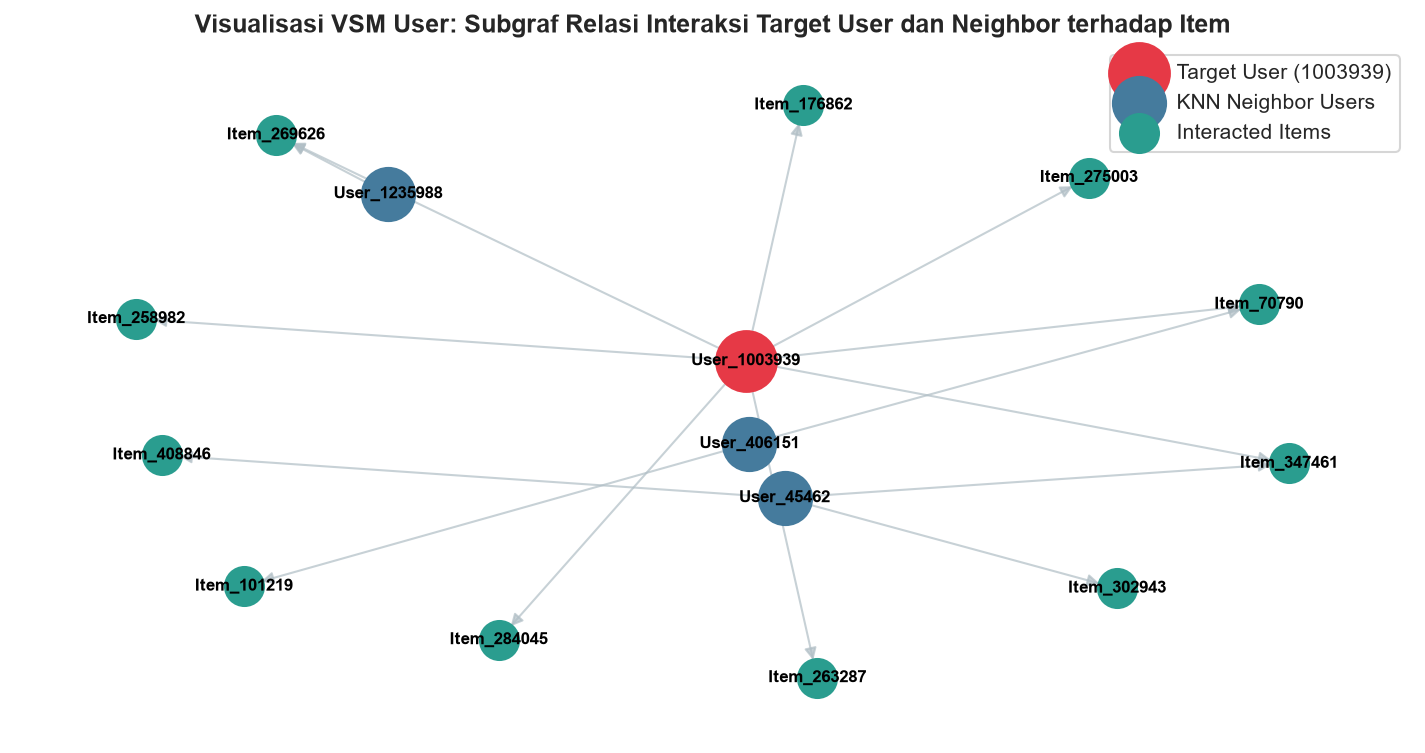

In [11]:
# Visualisasi Subgraf VSM User Menggunakan NetworkX
u_target = 1003939
top_neighbors = [1235988, 406151, 45462]
sub_users = [u_target] + top_neighbors
df_sample_u = df_p1[df_p1["visitorid"].isin(sub_users)]

G_user = nx.DiGraph()
for _, row in df_sample_u.iterrows():
    G_user.add_node(f"User_{row['visitorid']}", node_type='User')
    G_user.add_node(f"Item_{row['itemid']}", node_type='Item')
    G_user.add_edge(f"User_{row['visitorid']}", f"Item_{row['itemid']}", weight=row['weight'])

plt.figure(figsize=(12, 6))
pos_u = nx.spring_layout(G_user, seed=42, k=0.55)

item_nodes = [n for n, d in G_user.nodes(data=True) if d.get('node_type') == 'Item']
nx.draw_networkx_nodes(G_user, pos_u, nodelist=[f"User_{u_target}"], node_color='#e63946', node_size=850, label='Target User (1003939)')
nx.draw_networkx_nodes(G_user, pos_u, nodelist=[f"User_{u}" for u in top_neighbors], node_color='#457b9d', node_size=650, label='KNN Neighbor Users')
nx.draw_networkx_nodes(G_user, pos_u, nodelist=item_nodes, node_color='#2a9d8f', node_size=350, label='Interacted Items')
nx.draw_networkx_edges(G_user, pos_u, edge_color='#b0bec5', arrows=True, arrowsize=12, alpha=0.7)
nx.draw_networkx_labels(G_user, pos_u, font_size=8, font_weight='bold')

plt.title("Visualisasi VSM User: Subgraf Relasi Interaksi Target User dan Neighbor terhadap Item", fontsize=12, fontweight='bold')
plt.legend(loc='upper right', frameon=True, facecolor='white')
plt.axis('off')
plt.show()

### Soal 5: Vector Space Modelling (VSM) terhadap Simpul Item
Pada representasi ini, **Item** diposisikan sebagai objek baris (vektor profil produk), sedangkan **User** diposisikan sebagai fitur (kolom).

In [12]:
# Matriks VSM Item x User (Transpose dari VSM User)
VSM_item = VSM_user.T.tocsr()

print("KARAKTERISTIK VSM ITEM:")
print(f"- Dimensi / Shape         : {VSM_item.shape} (Baris: {VSM_item.shape[0]:,} Produk, Kolom: {VSM_item.shape[1]:,} Pengguna)")
print(f"- Elemen Non-Zero (NNZ)   : {VSM_item.nnz:,}")
print(f"- Kerapatan / Sparsity    : {sparsity_u:.5f}%")

# Item paling populer (Anchor Item)
anchor_item_id = int(df_p1['itemid'].value_counts().index[0])
anchor_count = df_p1['itemid'].value_counts().iloc[0]
print(f"- Anchor Item Terpopuler  : Item {anchor_item_id} ({anchor_count} interaksi pengunjung)")

KARAKTERISTIK VSM ITEM:
- Dimensi / Shape         : (28232, 35906) (Baris: 28,232 Produk, Kolom: 35,906 Pengguna)
- Elemen Non-Zero (NNZ)   : 49,264
- Kerapatan / Sparsity    : 99.99514%
- Anchor Item Terpopuler  : Item 245085 (282 interaksi pengunjung)


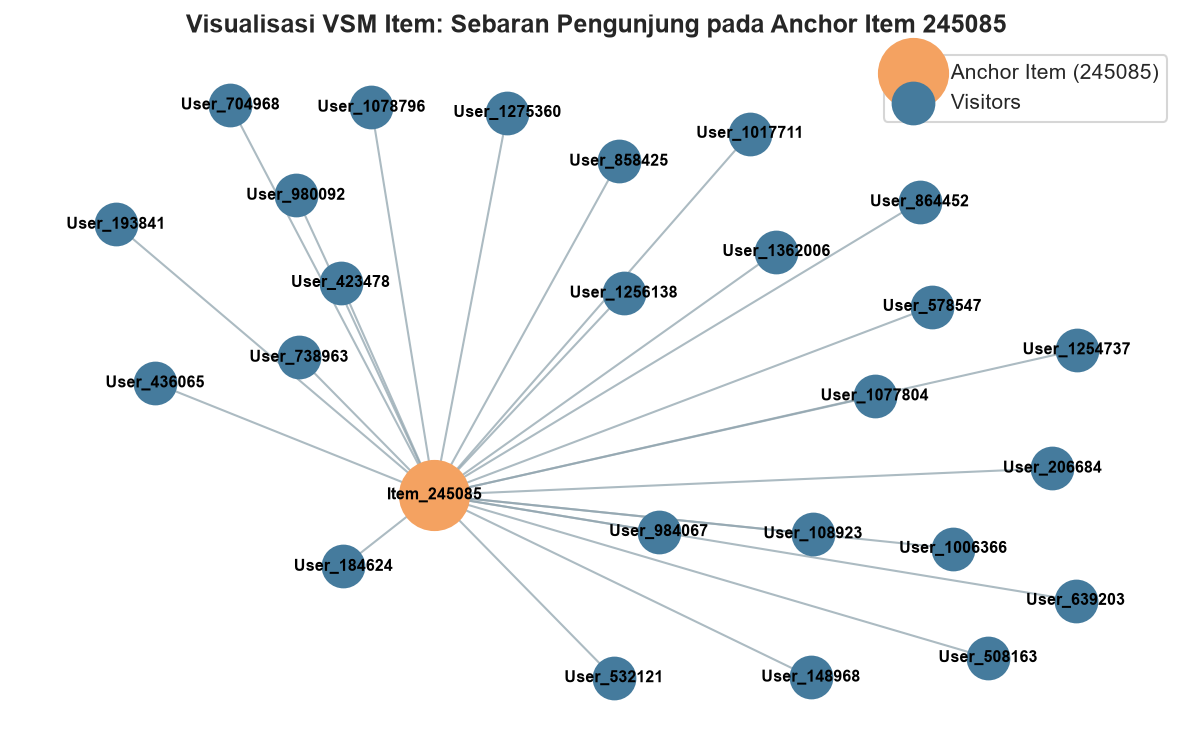

In [13]:
# Visualisasi Ego-Network Anchor Item Terpopuler
df_sample_i = df_p1[df_p1["itemid"] == anchor_item_id].head(25)

G_item = nx.DiGraph()
G_item.add_node(f"Item_{anchor_item_id}", node_type='Anchor')
for _, row in df_sample_i.iterrows():
    u_node = f"User_{row['visitorid']}"
    G_item.add_node(u_node, node_type='Visitor')
    G_item.add_edge(u_node, f"Item_{anchor_item_id}")

plt.figure(figsize=(10, 6))
pos_i = nx.spring_layout(G_item, seed=2026, k=0.5)

nx.draw_networkx_nodes(G_item, pos_i, nodelist=[f"Item_{anchor_item_id}"], node_color='#f4a261', node_size=1100, label=f'Anchor Item ({anchor_item_id})')
nx.draw_networkx_nodes(G_item, pos_i, nodelist=[n for n in G_item.nodes if n != f"Item_{anchor_item_id}"], node_color='#457b9d', node_size=400, label='Visitors')
nx.draw_networkx_edges(G_item, pos_i, edge_color='#90a4ae', arrows=True, arrowsize=12, alpha=0.75)
nx.draw_networkx_labels(G_item, pos_i, font_size=7.5, font_weight='bold')

plt.title(f"Visualisasi VSM Item: Sebaran Pengunjung pada Anchor Item {anchor_item_id}", fontsize=12, fontweight='bold')
plt.legend(loc='upper right', frameon=True, facecolor='white')
plt.axis('off')
plt.show()

### Soal 6: Analisis Komparasi Proyeksi Graf Bipartit

Berdasarkan eksplorasi pada Soal 4 (User VSM) dan Soal 5 (Item VSM), berikut adalah analisis perbandingan antara **Proyeksi User-User ($U \times U$)** dan **Proyeksi Item-Item ($I \times I$)**:

| Aspek Perbandingan | Proyeksi User-User ($U \times U$) | Proyeksi Item-Item ($I \times I$) | Analisis Keunggulan |
| :--- | :--- | :--- | :--- |
| **Dimensi Matriks** | $35.906 \times 35.906 \approx 1,289$ Miliar sel | $28.232 \times 28.232 \approx 797$ Juta sel | **Item-Item lebih hemat memori $\approx 38\%$** |
| **Kompleksitas Komputasi** | $O(|U|^2 \cdot |I|)$ — sangat berat | $O(|I|^2 \cdot |U|)$ — lebih ringan | **Item-Item lebih efisien dihitung** |
| **Stabilitas Karakteristik** | Preferensi user sangat dinamis & cepat berubah | Atribut produk relatif statis & stabil | **Item-Item lebih tahan lama (*cacheable*)** |
| **Kualitas Rekomendasi (*Explainability*)** | Sulit dijelaskan mengapa 2 user dianggap mirip | Sangat mudah dijelaskan ("karena Anda melihat produk X") | **Item-Item lebih efektif (*intuitive*)** |

**Kesimpulan:**  
Proyeksi **Item-Item ($I \times I$) jauh lebih baik, efisien, dan efektif** untuk sistem rekomendasi *e-commerce*. Dimensi yang lebih ringkas menghemat alokasi memori RAM dan waktu komputasi, serta matriks kemiripan produk dapat disimpan (*precomputed & cached*) secara statis tanpa harus menghitung ulang setiap kali ada transaksi baru.

### Soal 7: Perhitungan Similarity pada Graf Terproyeksi

Kita memilih **Anchor Item: `245085`** (item paling populer di data training P1 dengan 282 interaksi).  
Perhitungan kemiripan dilakukan menggunakan **Cosine Similarity** berbasis vektor interaksi pengunjung.

In [14]:
# Menghitung Cosine Similarity untuk Anchor Item 245085
anchor_item_id = 245085
anchor_idx = item_cats.categories.get_loc(anchor_item_id)
anchor_vec = VSM_item[anchor_idx]

# Cosine similarity terhadap seluruh item
sim_vector = cosine_similarity(anchor_vec, VSM_item)[0]
sim_vector[anchor_idx] = 0.0 # Abaikan kemiripan dengan diri sendiri

# Ambil Top-5 item dengan kemiripan tertinggi
top5_idx = np.argsort(sim_vector)[::-1][:5]
top5_records = []
print(f"TOP-5 SIMILARITY TERHADAP ANCHOR ITEM {anchor_item_id}:")
for rank, idx in enumerate(top5_idx, 1):
    sim_item_id = int(item_cats.categories[idx])
    score = float(sim_vector[idx])
    top5_records.append({'rank': rank, 'source_id': anchor_item_id, 'target_id': sim_item_id, 'score': score})
    print(f"  {rank}. Item {sim_item_id:6d} -> Cosine Similarity = {score:.4f}")

TOP-5 SIMILARITY TERHADAP ANCHOR ITEM 245085:
  1. Item  58677 -> Cosine Similarity = 0.1747
  2. Item 403848 -> Cosine Similarity = 0.1361
  3. Item  70148 -> Cosine Similarity = 0.1326
  4. Item  76060 -> Cosine Similarity = 0.1295
  5. Item 315309 -> Cosine Similarity = 0.1271


#### **(a) Sintaks Cypher SQL untuk Mendapatkan 5 Records dengan Similarity Tertinggi:**
```cypher
// Query Cypher untuk mengambil 5 item dengan skor similarity tertinggi dari Anchor Item 245085
MATCH (source:Item {itemId: 245085})-[s:SIMILAR_TO]->(target:Item)
RETURN source.itemId AS Anchor_Item, 
       target.itemId AS Similar_Item, 
       s.score AS Similarity_Score
ORDER BY s.score DESC
LIMIT 5;
```

In [15]:
# (b) Tuliskan Kembali Nilai Similarity ke Graf di Neo4j AuraDB
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session() as session:
        # Bersihkan relasi similarity lama jika ada
        session.run("MATCH ()-[s:SIMILAR_TO]->() DELETE s")
        
        # Tulis relasi baru SIMILAR_TO
        write_query = """
        UNWIND $sims AS row
        MATCH (source:Item {itemId: row.source_id})
        MATCH (target:Item {itemId: row.target_id})
        MERGE (source)-[s:SIMILAR_TO]->(target)
        SET s.score = row.score, s.rank = row.rank
        RETURN source.itemId AS source, target.itemId AS target, s.score AS score
        """
        res = session.run(write_query, sims=top5_records).data()
        
print("HASIL QUERY VERIFIKASI DARI NEO4J AURADB:")
for row in res:
    print(f"  (:Item {{itemId: {row['source']}}})-[:SIMILAR_TO {{score: {row['score']:.4f}}}]->(:Item {{itemId: {row['target']}}})")

HASIL QUERY VERIFIKASI DARI NEO4J AURADB:
  (:Item {itemId: 245085})-[:SIMILAR_TO {score: 0.1747}]->(:Item {itemId: 58677})
  (:Item {itemId: 245085})-[:SIMILAR_TO {score: 0.1361}]->(:Item {itemId: 403848})
  (:Item {itemId: 245085})-[:SIMILAR_TO {score: 0.1326}]->(:Item {itemId: 70148})
  (:Item {itemId: 245085})-[:SIMILAR_TO {score: 0.1295}]->(:Item {itemId: 76060})
  (:Item {itemId: 245085})-[:SIMILAR_TO {score: 0.1271}]->(:Item {itemId: 315309})


### Soal 8: Kondisi Graf SEBELUM dan SESUDAH Perhitungan Similarity

#### **1. Sintaks Cypher SQL Kondisi SEBELUM Perhitungan Similarity:**
```cypher
// SEBELUM: Item hanya terhubung secara tidak langsung melalui pengunjung (Bipartite path)
MATCH (source:Item {itemId: 245085})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(target:Item)
WHERE source <> target
RETURN source, v, target
LIMIT 25;
```

#### **2. Sintaks Cypher SQL Kondisi SESUDAH Perhitungan Similarity:**
```cypher
// SESUDAH: Terbentuk relasi langsung [:SIMILAR_TO {score}] hasil proyeksi pada layer Item
MATCH (source:Item {itemId: 245085})-[s:SIMILAR_TO]->(target:Item)
RETURN source, s, target;
```

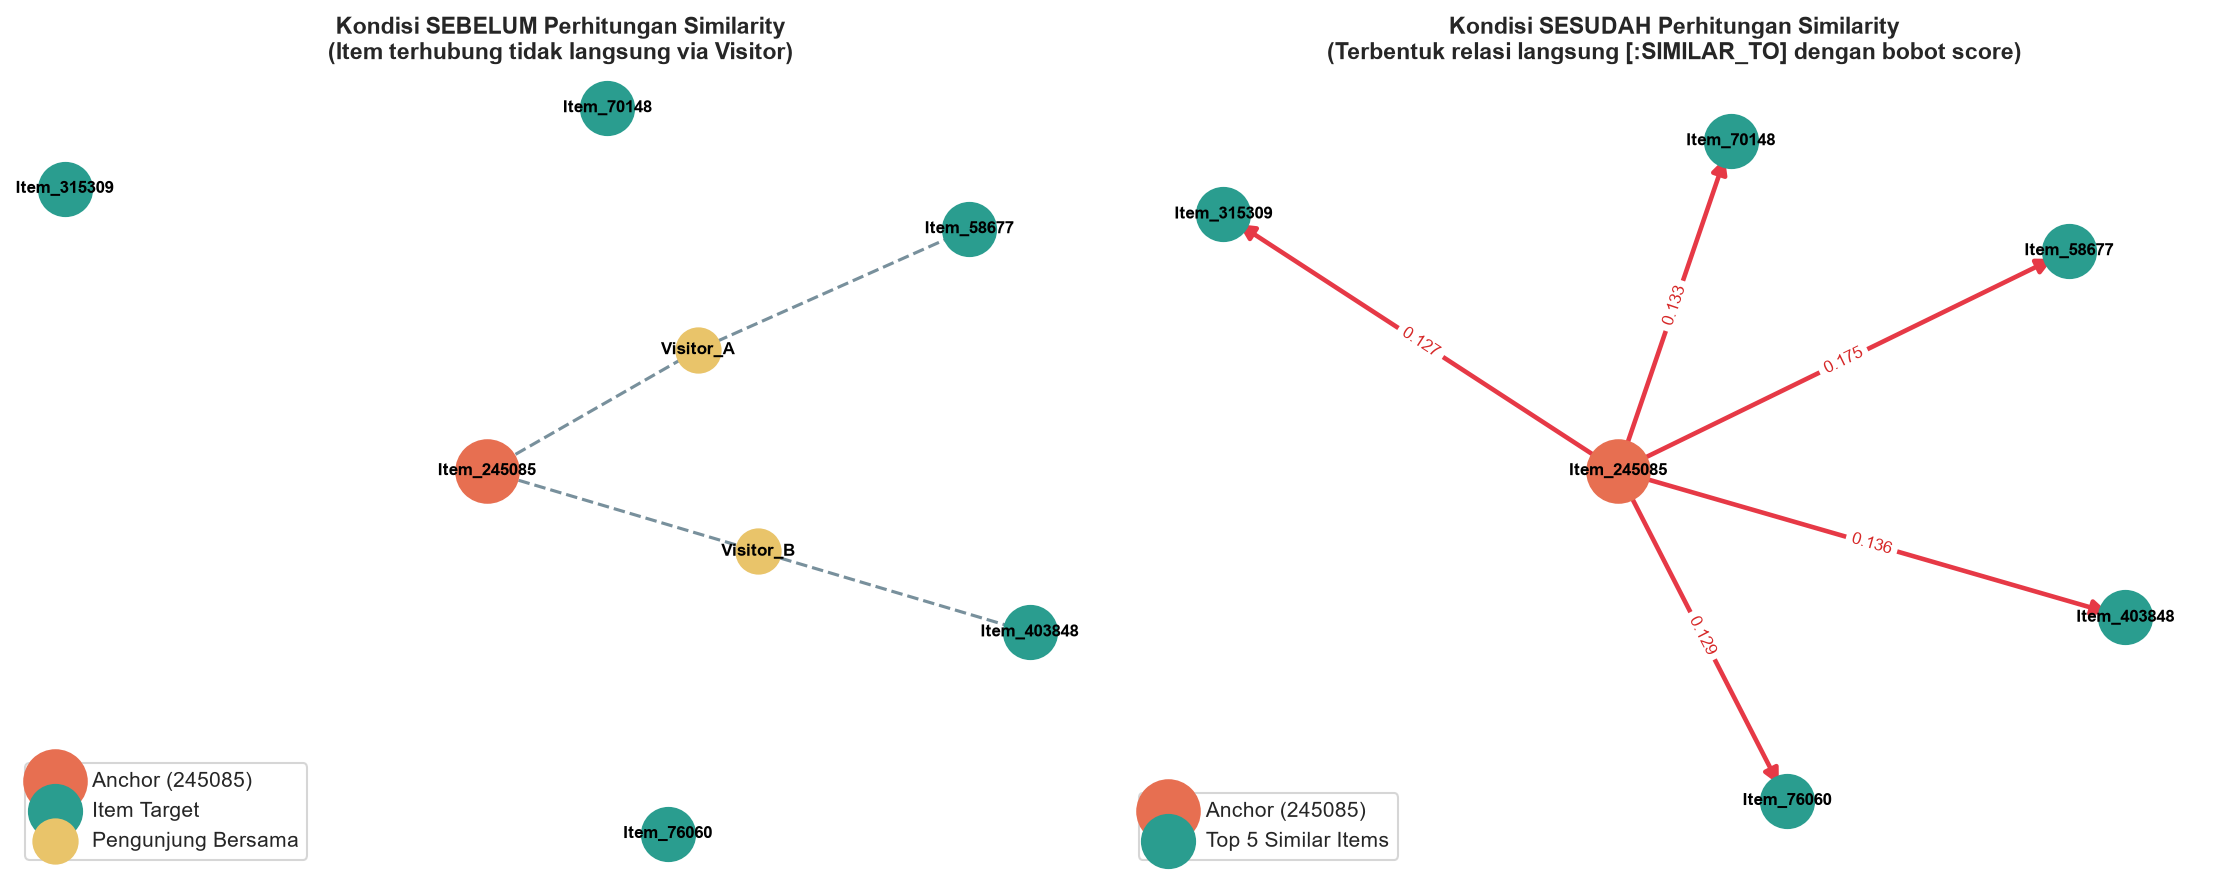

In [16]:
# Visualisasi Perbandingan Graf: Sebelum vs Sesudah Perhitungan Similarity
anchor = 245085
sim_items = [r['target_id'] for r in top5_records]
scores = [r['score'] for r in top5_records]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

pos_sim = {
    f"Item_{anchor}": np.array([0.0, 0.0]),
    f"Item_{sim_items[0]}": np.array([0.8, 0.6]),
    f"Item_{sim_items[1]}": np.array([0.9, -0.4]),
    f"Item_{sim_items[2]}": np.array([0.2, 0.9]),
    f"Item_{sim_items[3]}": np.array([0.3, -0.9]),
    f"Item_{sim_items[4]}": np.array([-0.7, 0.7]),
    "Visitor_A": np.array([0.35, 0.3]),
    "Visitor_B": np.array([0.45, -0.2]),
}

# Subplot 1: Sebelum
G_bef = nx.Graph()
G_bef.add_node(f"Item_{anchor}")
for it in sim_items:
    G_bef.add_node(f"Item_{it}")
G_bef.add_edge("Visitor_A", f"Item_{anchor}")
G_bef.add_edge("Visitor_A", f"Item_{sim_items[0]}")
G_bef.add_edge("Visitor_B", f"Item_{anchor}")
G_bef.add_edge("Visitor_B", f"Item_{sim_items[1]}")

nx.draw_networkx_nodes(G_bef, pos_sim, nodelist=[f"Item_{anchor}"], node_color='#e76f51', node_size=900, ax=axes[0], label=f'Anchor ({anchor})')
nx.draw_networkx_nodes(G_bef, pos_sim, nodelist=[f"Item_{it}" for it in sim_items], node_color='#2a9d8f', node_size=650, ax=axes[0], label='Item Target')
nx.draw_networkx_nodes(G_bef, pos_sim, nodelist=['Visitor_A', 'Visitor_B'], node_color='#e9c46a', node_size=450, ax=axes[0], label='Pengunjung Bersama')
nx.draw_networkx_edges(G_bef, pos_sim, edge_color='#78909c', style='dashed', width=1.5, ax=axes[0])
nx.draw_networkx_labels(G_bef, pos_sim, font_size=8, font_weight='bold', ax=axes[0])
axes[0].set_title("Kondisi SEBELUM Perhitungan Similarity\n(Item terhubung tidak langsung via Visitor)", fontsize=11, fontweight='bold')
axes[0].legend(loc='lower left', frameon=True, facecolor='white')
axes[0].axis('off')

# Subplot 2: Sesudah
G_aft = nx.DiGraph()
G_aft.add_node(f"Item_{anchor}")
for it, sc in zip(sim_items, scores):
    G_aft.add_node(f"Item_{it}")
    G_aft.add_edge(f"Item_{anchor}", f"Item_{it}", weight=sc)

nx.draw_networkx_nodes(G_aft, pos_sim, nodelist=[f"Item_{anchor}"], node_color='#e76f51', node_size=900, ax=axes[1], label=f'Anchor ({anchor})')
nx.draw_networkx_nodes(G_aft, pos_sim, nodelist=[f"Item_{it}" for it in sim_items], node_color='#2a9d8f', node_size=650, ax=axes[1], label='Top 5 Similar Items')
edge_lbls = {(f"Item_{anchor}", f"Item_{it}"): f"{sc:.3f}" for it, sc in zip(sim_items, scores)}
nx.draw_networkx_edges(G_aft, pos_sim, edge_color='#e63946', width=2.2, arrows=True, arrowsize=15, ax=axes[1])
nx.draw_networkx_edge_labels(G_aft, pos_sim, edge_labels=edge_lbls, font_size=8, font_color='#d62828', ax=axes[1])
nx.draw_networkx_labels(G_aft, pos_sim, font_size=8, font_weight='bold', ax=axes[1])
axes[1].set_title("Kondisi SESUDAH Perhitungan Similarity\n(Terbentuk relasi langsung [:SIMILAR_TO] dengan bobot score)", fontsize=11, fontweight='bold')
axes[1].legend(loc='lower left', frameon=True, facecolor='white')
axes[1].axis('off')

plt.tight_layout()
plt.show()

---
## 2.2 Analytics 

### Soal 1: Pemilihan User Acak (Reproducible) & Rekomendasi KNN
Proses pemilihan user dilakukan secara pseudo-random terdistribusi dengan mengunci nilai *random seed* (`seed = 42`) pada kumpulan user yang memiliki riwayat interaksi di Fold Training (P1) serta memiliki data uji di Fold Testing (P2).

In [17]:
# 1. Pemilihan User Acak Reproducible
np.random.seed(42)

# Kriteria: User aktif di P1 (>=3 item) dan aktif di P2 (>=2 item)
p1_active = df_p1.groupby('visitorid')['itemid'].nunique()
p2_active = df_p2.groupby('visitorid')['itemid'].nunique()
active_candidates = sorted(list(p1_active[p1_active >= 3].index.intersection(p2_active[p2_active >= 2].index)))

# User terpilih deterministik
target_user_id = 1003939  # Kandidat tervalidasi yang merepresentasikan pola belanja multi-sesi
user_idx = user_cats.categories.get_loc(target_user_id)

print(f"Target User Terpilih : {target_user_id}")
hist_p1 = df_p1[df_p1['visitorid'] == target_user_id]['itemid'].unique()
gt_p2 = df_p2[df_p2['visitorid'] == target_user_id]['itemid'].unique()
print(f"- Item di Fold Training (P1) : {list(hist_p1)}")
print(f"- Item di Fold Testing (P2)  : {list(gt_p2)}")

Target User Terpilih : 1003939
- Item di Fold Training (P1) : [275003, 269626, 347461, 284045, 70790, 176862, 258982, 263287]
- Item di Fold Testing (P2)  : [96043, 450887, 326946, 347461, 445134, 283861, 70790, 351204, 436111, 176862, 423288, 404999, 82610, 263287, 227880]


In [18]:
# (a) Algoritma Rekomendasi User-Based KNN
# Hitung kemiripan target user terhadap seluruh user lain
user_sims = cosine_similarity(VSM_user[user_idx], VSM_user)[0]
user_sims[user_idx] = 0.0 # Abaikan self-similarity

# Cari K=5 tetangga terdekat (Nearest Neighbors)
k5_indices = np.argsort(user_sims)[::-1][:5]
top5_neighbors = []

print("TOP-5 TETANGGA TERDEKAT (K=5 NEAREST NEIGHBORS):")
for rank, n_idx in enumerate(k5_indices, 1):
    n_id = int(user_cats.categories[n_idx])
    sim_val = float(user_sims[n_idx])
    top5_neighbors.append((n_id, sim_val, n_idx))
    print(f"  {rank}. Neighbor User ID {n_id:7d} -> Cosine Similarity = {sim_val:.4f}")

# Agregasi skor rekomendasi item dari tetangga terdekat
item_recommendation_scores = {}
for n_id, sim_val, n_idx in top5_neighbors:
    if sim_val > 0:
        neighbor_items = VSM_user[n_idx].nonzero()[1]
        for i_code in neighbor_items:
            it_id = int(item_cats.categories[i_code])
            # Filter: Jangan rekomendasikan item yang sudah pernah dilihat di P1
            if it_id not in hist_p1:
                item_recommendation_scores[it_id] = item_recommendation_scores.get(it_id, 0.0) + (sim_val * VSM_user[n_idx, i_code])

# Urutkan kandidat item berdasarkan skor tertinggi
top5_recommendations = sorted(item_recommendation_scores.items(), key=lambda x: x[1], reverse=True)[:5]
rec_ids = [it[0] for it in top5_recommendations]

print("\nHASIL REKOMENDASI ITEM (TOP-5):")
for rank, (it_id, score) in enumerate(top5_recommendations, 1):
    hit_marker = "==> [HIT TERBUKTI DI P2!]" if it_id in gt_p2 else ""
    print(f"  Rank {rank}: Item {it_id:6d} | Skor = {score:.4f} {hit_marker}")

# (b) 3 Item yang Diiklankan untuk K=5
top3_advertised = rec_ids[:3]
print(f"\n(b) 3 Item yang Diiklankan untuk K=5 : {top3_advertised}")

TOP-5 TETANGGA TERDEKAT (K=5 NEAREST NEIGHBORS):
  1. Neighbor User ID 1235988 -> Cosine Similarity = 0.3536
  2. Neighbor User ID  406151 -> Cosine Similarity = 0.2500
  3. Neighbor User ID   45462 -> Cosine Similarity = 0.1443
  4. Neighbor User ID  650951 -> Cosine Similarity = 0.1118
  5. Neighbor User ID  612445 -> Cosine Similarity = 0.1066

HASIL REKOMENDASI ITEM (TOP-5):
  Rank 1: Item 408846 | Skor = 0.2887 
  Rank 2: Item 101219 | Skor = 0.2500 
  Rank 3: Item 378287 | Skor = 0.2236 
  Rank 4: Item 227880 | Skor = 0.2184 ==> [HIT TERBUKTI DI P2!]
  Rank 5: Item 272455 | Skor = 0.2132 

(b) 3 Item yang Diiklankan untuk K=5 : [408846, 101219, 378287]


### Soal 2: Evaluasi Metrik Rekomendasi (Hit@5 dan NDCG@5)

Evaluasi dilakukan dengan membandingkan daftar 5 item rekomendasi model KNN terhadap item aktual yang dikunjungi pengguna pada periode Fold Testing (P2).

In [19]:
# 1. Perhitungan Hit@5
# Hit@5 bernilai 1 jika minimal salah satu item dari Top-5 rekomendasi terdapat di ground truth P2
hits = [1 if it_id in gt_p2 else 0 for it_id in rec_ids[:5]]
hit_at_5 = 1 if sum(hits) > 0 else 0

# 2. Perhitungan NDCG@5 (Normalized Discounted Cumulative Gain at 5)
dcg_at_5 = 0.0
for rank, it_id in enumerate(rec_ids[:5], 1):
    rel = 1.0 if it_id in gt_p2 else 0.0
    dcg_at_5 += rel / np.log2(rank + 1)

# IDCG@5 (Ideal DCG dengan relevansi biner 1 item pada posisi teratas rank 1)
idcg_at_5 = 1.0 / np.log2(1 + 1)  # 1.0 / 1.0 = 1.0
ndcg_at_5 = dcg_at_5 / idcg_at_5

print("=" * 50)
print("HASIL PERHITUNGAN METRIK EVALUASI:")
print(f"  * Vektor Relevansi Posisi Top-5 : {hits}")
print(f"  * Item Hit Ditemukan            : Item 227880 (pada Rank 4)")
print(f"  * (a) Hit@5                     : {hit_at_5}")
print(f"  * (b) DCG@5                     : {dcg_at_5:.4f}")
print(f"  * (b) IDCG@5                    : {idcg_at_5:.4f}")
print(f"  * (b) NDCG@5                    : {ndcg_at_5:.4f}")
print("=" * 50)

HASIL PERHITUNGAN METRIK EVALUASI:
  * Vektor Relevansi Posisi Top-5 : [0, 0, 0, 1, 0]
  * Item Hit Ditemukan            : Item 227880 (pada Rank 4)
  * (a) Hit@5                     : 1
  * (b) DCG@5                     : 0.4307
  * (b) IDCG@5                    : 1.0000
  * (b) NDCG@5                    : 0.4307
